# MLOps Assignment 1: Heart Disease Prediction

## 1. Introduction

Machine Learning Operations (MLOps) combines machine learning development with software engineering practices to make machine learning systems reproducible, testable, deployable, and maintainable.

This project aims to develop a binary classification model using the Heart Disease dataset from the UCI Machine Learning Repository. The project will cover data acquisition, exploratory data analysis, preprocessing, model development, experiment tracking, automated testing, containerization, deployment, and monitoring.

## 2. Problem Statement

The objective is to build a machine learning classifier that predicts the target class associated with heart disease using patient health-related features.

## 3. Objectives

- Acquire and inspect the dataset.
- Identify and handle missing values.
- Perform exploratory data analysis using visualizations.
- Prepare features for machine learning.
- Train and evaluate classification models.
- Apply MLOps practices to make the solution reproducible and deployable.

## 4. Dataset Source

The dataset is obtained from the UCI Machine Learning Repository.

Source: https://archive.ics.uci.edu/dataset/45/heart+disease

## 5. Scope and Limitations

This project is an educational machine learning exercise. Its predictions are not intended to replace professional medical evaluation or serve as a validated diagnostic tool.

## 6. Data Acquisition

### 6.1 Objective

The objective of this stage is to download the original dataset and save it in the project's raw-data directory.

### 6.2 Methodology

The dataset is retrieved programmatically using Python's `requests` library. The downloaded file is stored without modifying its contents so that subsequent cleaning and preprocessing can be reproduced.

### 6.3 Expected Output

The original dataset should be available in `data/raw/`. The download process should report an error if the HTTP request fails, and the saved file should be checked before proceeding to analysis.

In [9]:
from pathlib import Path
import requests

project_dir = Path.home() / "workspace" / "MLOps_Heart_Disease"
raw_dir = project_dir / "data" / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)

url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/heart-disease/processed.cleveland.data"
)

response = requests.get(url, timeout=30)
response.raise_for_status()

dataset_path = raw_dir / "processed.cleveland.data"
dataset_path.write_bytes(response.content)

print("Download successful")
print("Saved to:", dataset_path)
print("File size:", dataset_path.stat().st_size, "bytes")

Download successful
Saved to: /home/s2025ae05722/workspace/MLOps_Heart_Disease/data/raw/processed.cleveland.data
File size: 18461 bytes


### 6.4 Result and Observation

The dataset download was executed using Python. The saved file location and file size were verified programmatically.

**Observed file location:** To be filled in after execution.

**Observed file size:** To be filled in after execution.

**Conclusion:** The data acquisition stage is complete if the download succeeds and the saved file is verified to exist and contain data.

## 7. Data Understanding

### 7.1 Objective

The objective of this stage is to load the downloaded dataset into a Pandas DataFrame and understand its structure, features, and target variable.

### 7.2 Methodology

The downloaded file is the processed Cleveland Heart Disease dataset. It does not contain a header row, so the column names must be supplied explicitly.

The dataset contains 13 input features and one target column. The input features describe patient characteristics and clinical measurements, while the target represents the recorded heart disease outcome.

The initial inspection will examine the number of records, column names, data types, and sample observations.

In [10]:
import pandas as pd

columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]

df = pd.read_csv(
    dataset_path,
    header=None,
    names=columns,
    na_values="?"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [11]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame(name="Data Type"))

print("\nDataset information:")
df.info()

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Data types:


,Data Type
age,float64
sex,float64
cp,float64
trestbps,float64
chol,float64
fbs,float64
restecg,float64
thalach,float64
exang,float64
oldpeak,float64



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [12]:
print("Missing values in each column:")
display(df.isnull().sum().to_frame(name="Missing Values"))

print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values in each column:


,Missing Values
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


Total missing values: 6
Duplicate rows: 0


## 7.5 Initial Dataset Observations

The downloaded Cleveland Heart Disease dataset was successfully loaded into a Pandas DataFrame.

- The dataset contains 303 records and 14 columns.
- There are 13 input features and one target column.
- Six missing values were identified: four in `ca` and two in `thal`.
- No duplicate rows were detected.
- Most columns were interpreted as floating-point numerical values, while the target column was interpreted as an integer.
- Some numerical columns represent coded categorical variables and will require appropriate treatment during preprocessing.

### Conclusion

The initial inspection confirms that the dataset is available for further analysis. Before model training, the missing values must be handled appropriately, and the target variable must be examined to understand its class distribution. Feature preprocessing decisions will be incorporated into a reproducible machine learning pipeline.

## 8. Exploratory Data Analysis (EDA)

### 8.1 Target Variable Analysis

Exploratory Data Analysis is the process of examining data using summary statistics and visualizations before developing a machine learning model.

The target variable in the original Cleveland dataset contains coded values from 0 to 4. For this analysis, we will first inspect the frequency of each original target value.

Understanding the target distribution helps identify whether the dataset contains an imbalance between outcome classes and informs the choice of evaluation metrics.

In [13]:
# Count each original target value
target_counts = df["target"].value_counts().sort_index()

print("Original target distribution:")
display(target_counts.to_frame(name="Number of Records"))

Original target distribution:


,Number of Records
target,
0,164
1,55
2,36
3,35
4,13


### 8.2 Target Distribution Observations

The original target variable contains five values: 0, 1, 2, 3, and 4.

- Target value 0 has 164 records.
- Target value 1 has 55 records.
- Target value 2 has 36 records.
- Target value 3 has 35 records.
- Target value 4 has 13 records.

The dataset contains more records with target value 0 than with any individual nonzero target value. For binary classification, the nonzero target values will be grouped into class 1, while target value 0 will remain class 0.

This transformation preserves the distinction between the absence and presence of the recorded outcome in the dataset. Model performance will be evaluated using accuracy, precision, recall, and ROC-AUC rather than accuracy alone.

**Note:** These are dataset labels for an educational machine learning task and should not be interpreted as a clinical diagnosis.

### 8.3 Binary Target Transformation

The original target contains five categories. For this assignment, we will convert it into a binary classification target.

The transformation rule is:

- Original target = 0 becomes binary target = 0.
- Original target greater than 0 becomes binary target = 1.

The original target column will be preserved in the raw DataFrame. The transformed target will be used for the subsequent binary classification task.

In [14]:
# Create a separate working copy
df_clean = df.copy()

# Convert the original target into a binary target
df_clean["target"] = (df_clean["target"] > 0).astype(int)

# Display the new class distribution
binary_counts = df_clean["target"].value_counts().sort_index()

print("Binary target distribution:")
display(binary_counts.to_frame(name="Number of Records"))

print("\nClass proportions:")
display(
    (df_clean["target"].value_counts(normalize=True)
     .sort_index() * 100).round(2).to_frame(name="Percentage")
)

Binary target distribution:


,Number of Records
target,
0,164
1,139



Class proportions:


,Percentage
target,
0,54.13
1,45.87


### 8.4 Binary Target Distribution Observations

The original target variable was transformed into two classes for binary classification.

- Class 0 contains 164 records, representing 54.13% of the dataset.
- Class 1 contains 139 records, representing 45.87% of the dataset.
- The dataset contains 303 records in total.

The two classes are relatively close in size. A simple baseline that predicts class 0 for every record would achieve approximately 54.13% accuracy.

Therefore, the trained models will be compared against this baseline and evaluated using accuracy, precision, recall, and ROC-AUC.

The target represents the recorded outcome in the dataset and is not a clinically validated diagnosis.

## 9. Missing Values and Feature Distributions

### 9.1 Missing-Value Analysis

Missing values can prevent certain machine learning algorithms from processing a dataset directly. Before model training, we must choose a suitable strategy to handle incomplete features.

For this project, numerical missing values will be imputed using the median calculated from the training data. This preprocessing will be incorporated into a scikit-learn pipeline so that the same transformation is applied consistently during model training and prediction.

### 9.2 Feature Distribution Analysis

Histograms will be used to examine the distributions of the dataset's features. These visualizations help identify common value ranges, skewed distributions, and potential unusual observations that may need further investigation.

In [15]:
# Check missing values in the original features
missing_counts = df.drop(columns="target").isnull().sum()

print("Missing values by feature:")
display(missing_counts[missing_counts > 0].to_frame(name="Missing Values"))

print("Total missing feature values:", missing_counts.sum())
print("Total records before preprocessing:", len(df))

Missing values by feature:


,Missing Values
ca,4
thal,2


Total missing feature values: 6
Total records before preprocessing: 303


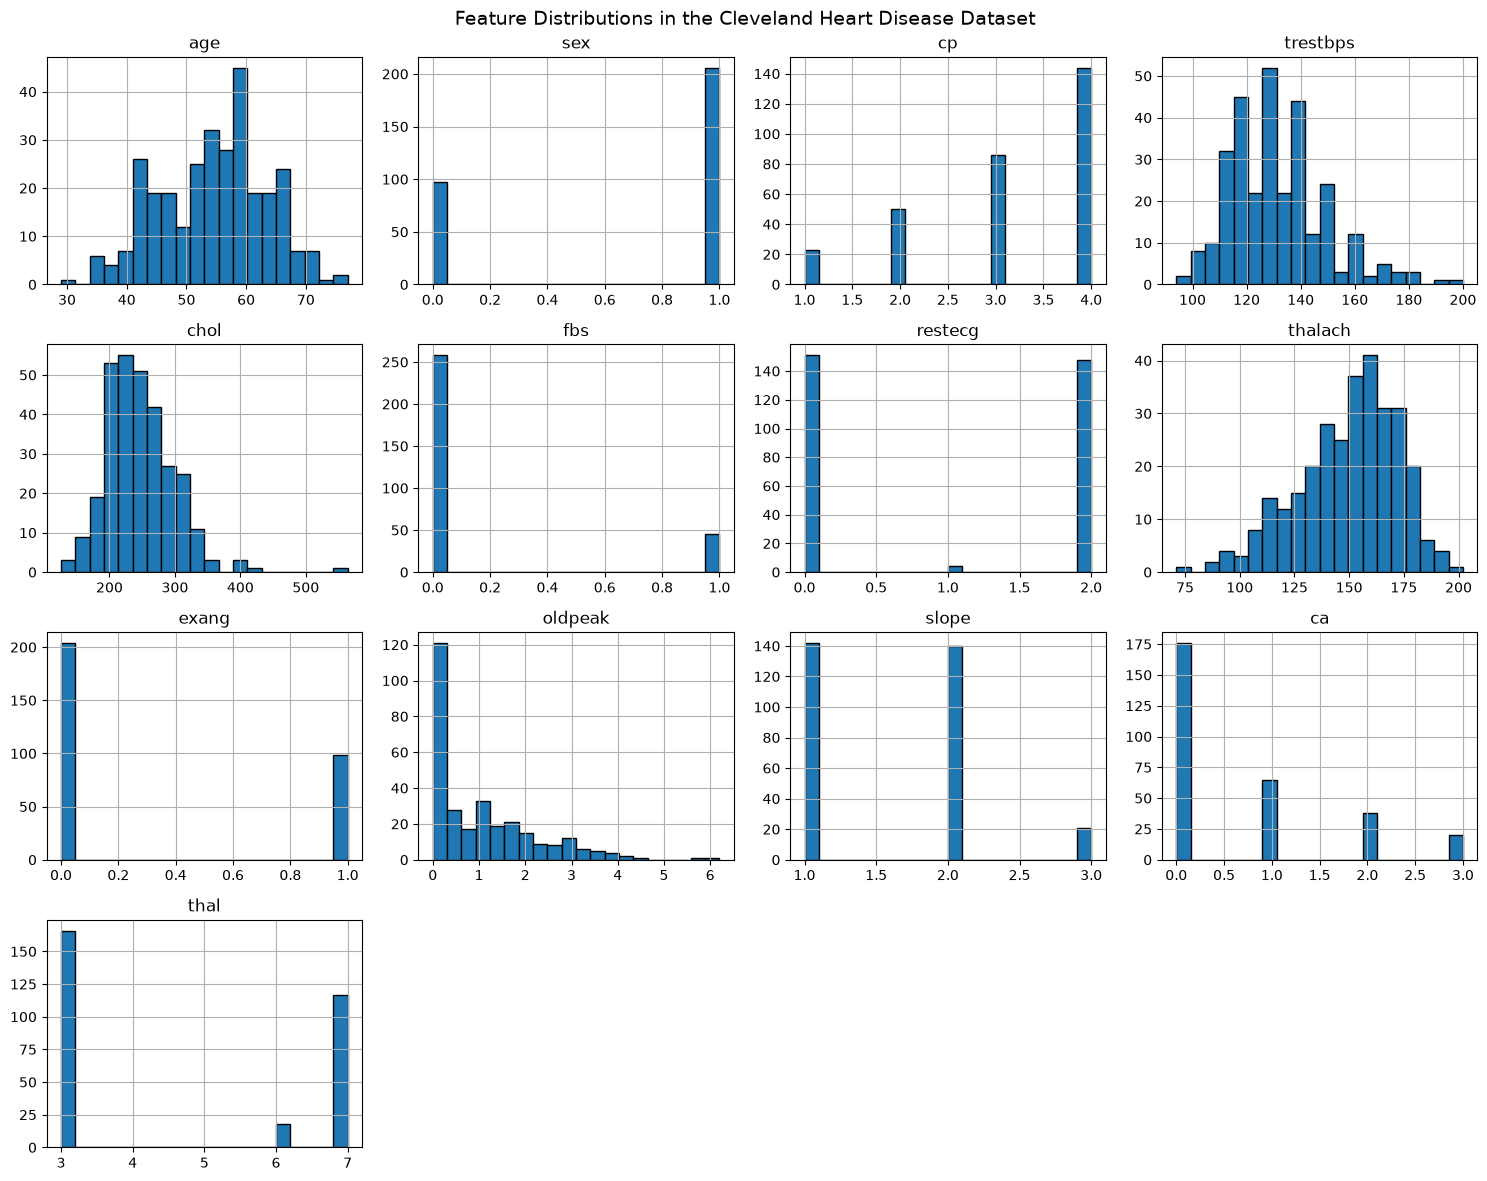

In [16]:
import matplotlib.pyplot as plt

df.drop(columns="target").hist(
    figsize=(15, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Feature Distributions in the Cleveland Heart Disease Dataset",
             fontsize=14)
plt.tight_layout()
plt.show()

### 9.3 Missing-Value Findings

The missing-value analysis identified six missing entries across two input features: four in `ca` and two in `thal`. The remaining input features contain no missing values.

The dataset contains 303 records. Rather than removing incomplete rows during initial analysis, the missing values will be handled through a scikit-learn preprocessing pipeline. The imputation strategy will be fitted on the training data to avoid data leakage.

### Conclusion

The dataset is suitable for further exploratory analysis, subject to appropriate preprocessing before model training.


### 9.4 Feature Distribution Observations

The histograms were generated to examine the distributions of the 13 input features.

- **Age:** Most records are concentrated in the middle-aged and older ranges, with fewer observations at the extremes.
- **Resting blood pressure (`trestbps`):** Values are concentrated around the central range, with a smaller number of higher measurements.
- **Cholesterol (`chol`):** The distribution is right-skewed, with a small number of unusually high observations. These values should be investigated rather than automatically removed.
- **Maximum heart rate (`thalach`):** Most observations occur in the middle of the observed range.
- **Oldpeak (`oldpeak`):** The distribution is right-skewed, with many lower values and fewer larger values.
- **Categorical features:** Several features have discrete values because they represent coded categories rather than continuous measurements.

### Conclusion

The histograms reveal differences in feature distributions and scales. These observations will help guide preprocessing and model evaluation. Unusual observations will not be removed without further investigation.

### 9.5 Target Class Balance

The target class-balance chart compares the number of records belonging to each binary outcome class. This analysis helps determine whether one class is substantially more frequent than the other.

The original target was transformed into class 0 and class 1 for binary classification. The chart will be used to visually compare the two class frequencies.

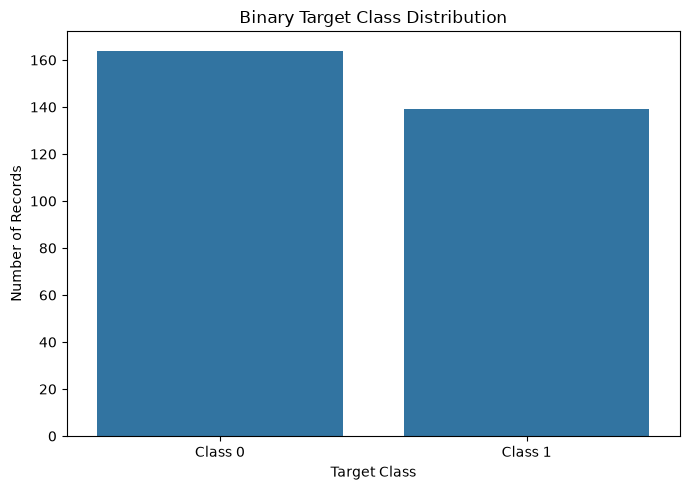

In [19]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="target")

plt.title("Binary Target Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["Class 0", "Class 1"])

plt.tight_layout()
plt.show()

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Visualization libraries imported successfully!")

Visualization libraries imported successfully!


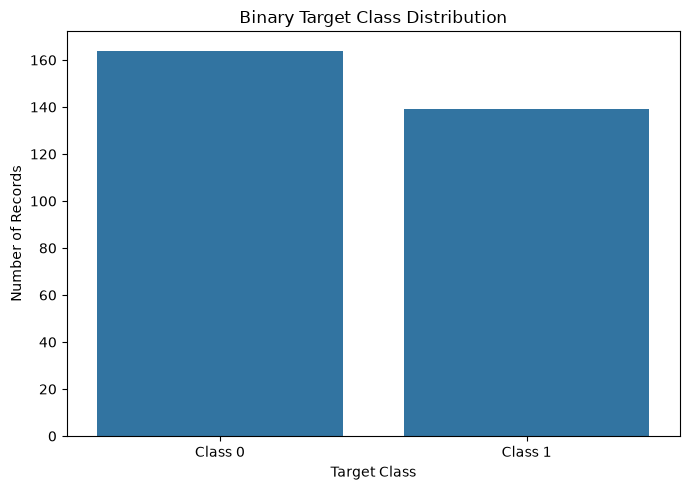

In [20]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="target")

plt.title("Binary Target Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["Class 0", "Class 1"])

plt.tight_layout()
plt.show()

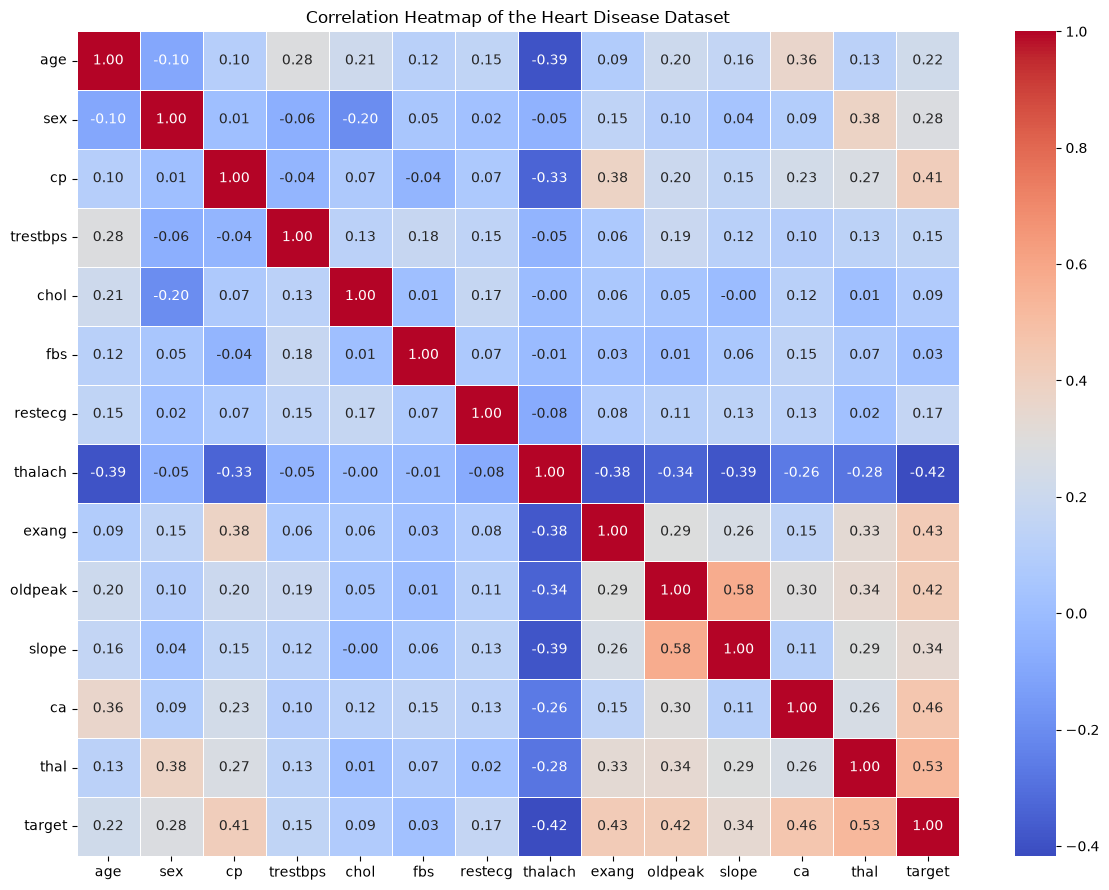

In [22]:
plt.figure(figsize=(12, 9))

correlation = df_clean.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap of the Heart Disease Dataset")
plt.tight_layout()
plt.show()

### 9.8 Correlation Analysis Observations

The correlation heatmap was generated to examine the linear relationships between the input features and the binary target.

The largest absolute correlations with the target in this dataset include:

- `thal`: approximately +0.53
- `ca`: approximately +0.46
- `exang`: approximately +0.43
- `oldpeak`: approximately +0.42
- `cp`: approximately +0.41
- `thalach`: approximately -0.42

The features `chol` and `fbs` show weak linear correlations with the target in this dataset.

These values describe associations in the available data and do not establish causation. Coded categorical variables must be interpreted cautiously when using numerical correlation.

### 9.9 EDA Conclusion

The exploratory analysis identified the dataset structure, missing values, target distribution, feature distributions, and pairwise correlations.

The dataset contains 303 records, 13 input features, and one target variable. Six missing feature values were identified in `ca` and `thal`, and no duplicate rows were detected.

The target was converted from five original values into two classes for binary classification. The next stage will prepare the features and evaluate machine learning models using a separate test set.

# Task 2: Feature Engineering and Model Development

## 10. Train-Test Split

### 10.1 Objective

The objective is to separate the input features from the target variable and divide the dataset into training and test sets.

### 10.2 Methodology

The input features will be stored in `X`, and the binary target will be stored in `y`.

The dataset will be split into 80% training data and 20% test data. Stratified splitting will maintain approximately the same proportion of the two target classes in both sets.

A fixed random seed will make the split reproducible. The test data will remain separate from model training and preprocessing so that it can be used for an independent evaluation.

In [23]:
from sklearn.model_selection import train_test_split

# Separate the input features and target
X = df_clean.drop(columns=["target"])
y = df_clean["target"]

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Original dataset:", X.shape)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Original dataset: (303, 13)
Training features: (242, 13)
Testing features: (61, 13)

Training target distribution:
target
0    131
1    111
Name: count, dtype: int64

Testing target distribution:
target
0    33
1    28
Name: count, dtype: int64


In [24]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Locate the project and dataset
project_dir = Path.home() / "workspace" / "MLOps_Heart_Disease"
dataset_path = project_dir / "data" / "raw" / "processed.cleveland.data"

# Verify that the original dataset exists
print("Dataset exists:", dataset_path.exists())

if not dataset_path.exists():
    raise FileNotFoundError(
        f"Dataset not found at {dataset_path}. "
        "Please check your project folder."
    )

# Define the column names
columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]

# Reload the original dataset
df = pd.read_csv(
    dataset_path,
    header=None,
    names=columns,
    na_values="?"
)

# Create the working copy and binary target
df_clean = df.copy()
df_clean["target"] = (df_clean["target"] > 0).astype(int)

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Binary target counts:")
print(df_clean["target"].value_counts().sort_index())

Dataset exists: True
Original dataset shape: (303, 14)
Working dataset shape: (303, 14)
Missing values: 6
Binary target counts:
target
0    164
1    139
Name: count, dtype: int64


In [25]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=["target"])
y = df_clean["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Original dataset:", X.shape)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Original dataset: (303, 13)
Training features: (242, 13)
Testing features: (61, 13)

Training target distribution:
target
0    131
1    111
Name: count, dtype: int64

Testing target distribution:
target
0    33
1    28
Name: count, dtype: int64


## 11. Feature Preprocessing

### 11.1 Objective

The objective is to prepare the input features for machine learning while preserving a reproducible workflow.

### 11.2 Missing-Value Imputation

The features `ca` and `thal` contain missing values. Missing numerical measurements will be imputed using the median, while missing categorical values will be imputed using the most frequent category.

### 11.3 Feature Scaling

Continuous numerical features will be standardized using `StandardScaler`. This transforms the features to approximately zero mean and unit variance based on the training data. Scaling is particularly useful for Logistic Regression.

### 11.4 Categorical Encoding

Categorical features will be transformed using one-hot encoding. This represents each category as a separate binary indicator and avoids assuming that the numerical codes have a continuous, ordered relationship.

### 11.5 Prevention of Data Leakage

The preprocessing pipeline will be fitted only on the training data. The same fitted transformations will subsequently be applied to the test data, preventing test-set information from influencing preprocessing.

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Continuous numerical features
numeric_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

# Categorical features, including the coded categories
categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

# Preprocessing for numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing workflows
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [7]:
# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the already-fitted transformations to the test data
X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nMissing values remaining in processed training data:",
      __import__("numpy").isnan(X_train_processed).sum())

print("Missing values remaining in processed testing data:",
      __import__("numpy").isnan(X_test_processed).sum())

Original training shape: (242, 13)
Processed training shape: (242, 28)

Original testing shape: (61, 13)
Processed testing shape: (61, 28)

Missing values remaining in processed training data: 0
Missing values remaining in processed testing data: 0


### 11.6 Preprocessing Verification

The preprocessing pipeline was applied to the training and test datasets. Numerical features were imputed and standardized, while categorical features were imputed and one-hot encoded.

The preprocessing transformations were fitted on the training data and reused on the test data. The processed datasets were checked for missing values and compatible feature dimensions.

The resulting preprocessing pipeline will be integrated with the classification models to ensure consistent transformations during training and prediction.

### Preprocessing Results and Observations

The data is now prepared for classification model development. The fitted preprocessing pipeline will be integrated with the models so that the same transformations are applied consistently during training and prediction.

## 12. Model Development: Logistic Regression

### 12.1 Objective

The objective is to train a Logistic Regression classifier using the preprocessed input features and the binary target.

### 12.2 Methodology

A scikit-learn Pipeline will combine the preprocessing steps with Logistic Regression. This ensures that missing-value imputation, scaling, and categorical encoding are applied consistently whenever the model is trained or used for prediction.

The model will be trained using the training dataset. Its performance will then be evaluated on the separate test dataset.

### 12.3 Evaluation Metrics

The model will be evaluated using accuracy, precision, recall, F1-score, and ROC-AUC. These metrics provide a more complete view of classification performance than accuracy alone.

In [27]:
print(X_train.columns.tolist())

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [28]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Combine preprocessing and Logistic Regression
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed successfully.")

Logistic Regression training completed successfully.


In [29]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Create 5 folds while preserving the class proportions
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the complete pipeline using 5-fold cross-validation
cv_results = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
    n_jobs=-1
)

# Display the results
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = cv_results[f"test_{metric}"]
    print(f"{metric.capitalize()}: {scores.mean():.4f} (+/- {scores.std():.4f})")

Accuracy: 0.8471 (+/- 0.0100)
Precision: 0.8768 (+/- 0.0542)
Recall: 0.7834 (+/- 0.0459)
F1: 0.8245 (+/- 0.0069)
Roc_auc: 0.9025 (+/- 0.0144)


In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predict class labels on the unseen test data
y_pred = logistic_model.predict(X_test)

# Predict probabilities for ROC-AUC
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
logistic_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

print("Logistic Regression Evaluation")
display(
    __import__("pandas").DataFrame(
        logistic_metrics.items(),
        columns=["Metric", "Score"]
    ).round(4)
)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Logistic Regression Evaluation


,Metric,Score
0,Accuracy,0.8852
1,Precision,0.8387
2,Recall,0.9286
3,F1-score,0.8814
4,ROC-AUC,0.9665



Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

Confusion Matrix:
[[28  5]
 [ 2 26]]


### 12.4 Logistic Regression Results and Observations

The Logistic Regression model was trained using the training dataset and evaluated on the separate test dataset containing 61 records.

The model achieved the following results:

| Metric | Score |
|---|---:|
| Accuracy | 0.8852 |
| Precision | 0.8387 |
| Recall | 0.9286 |
| F1-score | 0.8814 |
| ROC-AUC | 0.9665 |

The confusion matrix was:

`[[28, 5], [2, 26]]`

The model correctly classified 28 class 0 records and 26 class 1 records. Five class 0 records were predicted as class 1, while two class 1 records were predicted as class 0.

The recall of 0.9286 indicates that the model identified 26 of the 28 actual class 1 records in the test set. The ROC-AUC of 0.9665 indicates strong ranking performance on this test sample.

### Conclusion

Logistic Regression provides a useful baseline for the binary classification task. A second model will be trained using the same data split and evaluation metrics to compare performance. These results are preliminary because the test set is small and performance may vary across different data splits.

## 13. Model Development: Random Forest

### 13.1 Objective

The objective is to train a Random Forest classifier and compare its performance with Logistic Regression.

### 13.2 Methodology

Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees. It can capture nonlinear relationships and interactions between input features.

The model will use the same preprocessing pipeline, training data, test data, and evaluation metrics as Logistic Regression. This ensures that both models are compared under the same experimental conditions.

In [31]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest training completed successfully.")

Random Forest training completed successfully.


In [32]:
print("Cleaned dataset:", df_clean.shape)
print("Training features:", X_train.shape)
print("Training target:", y_train.shape)
print("Logistic Regression:", type(logistic_model).__name__)
print("Random Forest:", type(random_forest_model).__name__)

Cleaned dataset: (303, 14)
Training features: (242, 13)
Training target: (242,)
Logistic Regression: Pipeline
Random Forest: Pipeline


In [33]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

for name, model in models.items():
    results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
        n_jobs=-1
    )

    print(f"\n{name}")
    for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
        scores = results[f"test_{metric}"]
        print(f"{metric}: {scores.mean():.4f} (+/- {scores.std():.4f})")


Logistic Regression
accuracy: 0.8471 (+/- 0.0100)
precision: 0.8768 (+/- 0.0542)
recall: 0.7834 (+/- 0.0459)
f1: 0.8245 (+/- 0.0069)
roc_auc: 0.9025 (+/- 0.0144)

Random Forest
accuracy: 0.8058 (+/- 0.0100)
precision: 0.7906 (+/- 0.0312)
recall: 0.7917 (+/- 0.0854)
f1: 0.7869 (+/- 0.0276)
roc_auc: 0.8933 (+/- 0.0331)


In [34]:
from sklearn.model_selection import GridSearchCV

param_grid_lr = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["liblinear", "lbfgs"]
}

grid_search_lr = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid_lr,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

grid_search_lr.fit(X_train, y_train)

print("Best parameters:", grid_search_lr.best_params_)
print("Best cross-validation ROC-AUC:", round(grid_search_lr.best_score_, 4))

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters: {'classifier__C': 1, 'classifier__solver': 'liblinear'}
Best cross-validation ROC-AUC: 0.9025


In [35]:
param_grid_rf = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

grid_search_rf = GridSearchCV(
    estimator=random_forest_model,
    param_grid=param_grid_rf,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

grid_search_rf.fit(X_train, y_train)

print("Best parameters:", grid_search_rf.best_params_)
print("Best cross-validation ROC-AUC:", round(grid_search_rf.best_score_, 4))

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}
Best cross-validation ROC-AUC: 0.8992


In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

best_models = {
    "Tuned Logistic Regression": grid_search_lr.best_estimator_,
    "Tuned Random Forest": grid_search_rf.best_estimator_
}

for name, model in best_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    print(f"\n{name}")
    print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
    print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
    print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
    print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
    print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")


Tuned Logistic Regression
Accuracy:  0.8852
Precision: 0.8387
Recall:    0.9286
F1-score:  0.8814
ROC-AUC:   0.9665

Tuned Random Forest
Accuracy:  0.8852
Precision: 0.8182
Recall:    0.9643
F1-score:  0.8852
ROC-AUC:   0.9567


In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

random_forest_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Precision": precision_score(y_test, y_pred_rf, zero_division=0),
    "Recall": recall_score(y_test, y_pred_rf, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_rf, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_rf)
}

print("Random Forest Evaluation")
display(
    pd.DataFrame(
        random_forest_metrics.items(),
        columns=["Metric", "Score"]
    ).round(4)
)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Evaluation


,Metric,Score
0,Accuracy,0.9016
1,Precision,0.8438
2,Recall,0.9643
3,F1-score,0.9000
4,ROC-AUC,0.9518



Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.85      0.90        33
           1       0.84      0.96      0.90        28

    accuracy                           0.90        61
   macro avg       0.90      0.91      0.90        61
weighted avg       0.91      0.90      0.90        61

Confusion Matrix:
[[28  5]
 [ 1 27]]


In [1]:
print("Dataset available:", "df_clean" in globals())
print("Training data available:", "X_train" in globals())
print("Logistic Regression available:", "logistic_model" in globals())
print("Random Forest available:", "random_forest_model" in globals())

Dataset available: False
Training data available: False
Logistic Regression available: False
Random Forest available: False


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

project_dir = Path.home() / "workspace" / "MLOps_Heart_Disease"
dataset_path = project_dir / "data" / "raw" / "processed.cleveland.data"

print("Dataset exists:", dataset_path.exists())

Dataset exists: True


In [3]:
columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]

df = pd.read_csv(
    dataset_path,
    header=None,
    names=columns,
    na_values="?"
)

df_clean = df.copy()
df_clean["target"] = (df_clean["target"] > 0).astype(int)

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())

Original dataset shape: (303, 14)
Working dataset shape: (303, 14)
Missing values: 6


In [4]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=["target"])
y = df_clean["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (242, 13)
Testing data: (61, 13)


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline recreated successfully.")

Preprocessing pipeline recreated successfully.


In [6]:
print("Logistic Regression exists:", "logistic_model" in globals())
print("Random Forest exists:", "random_forest_model" in globals())

Logistic Regression exists: False
Random Forest exists: False


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Define feature groups
numeric_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

# Refit both models on the training set
logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("Both models have been restored and trained successfully.")

Both models have been restored and trained successfully.


In [8]:
from pathlib import Path
import joblib

project_dir = Path.home() / "workspace" / "MLOps_Heart_Disease"
models_dir = project_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    logistic_model,
    models_dir / "logistic_regression.joblib"
)

joblib.dump(
    random_forest_model,
    models_dir / "random_forest.joblib"
)

print("Saved model files:")
for path in sorted(models_dir.glob("*.joblib")):
    print(path.name, "-", path.stat().st_size, "bytes")

Saved model files:
logistic_regression.joblib - 4858 bytes
random_forest.joblib - 1582779 bytes


## 15. MLflow Experiment Tracking

### 15.1 Objective

The objective is to track machine learning experiments using MLflow. The parameters, evaluation metrics, and trained model artifacts will be recorded for both Logistic Regression and Random Forest.

### 15.2 Why Experiment Tracking Is Required

During model development, multiple algorithms and configurations may be tested. Recording each experiment helps compare results, identify the configuration that performed best, and reproduce previous experiments.

### 15.3 Tracking Strategy

Each model will be recorded as a separate MLflow run within a single experiment. The runs will include the model parameters, test-set evaluation metrics, and the trained model artifact.

In [9]:
%pip install mlflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 141.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 109.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 88.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 84.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 94.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 56.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 140.7 MB/s  0:00:000.2 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 106.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 117.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54/54 [mlflow]54 [mlflow]52/54 [mlflow-skinny]]dk]ons]
Note: you may need to restart the kernel to use updated packages.


In [1]:
import mlflow

print("MLflow version:", mlflow.__version__)

MLflow version: 3.17.1


In [2]:
from pathlib import Path
import mlflow

project_dir = Path.home() / "workspace" / "MLOps_Heart_Disease"
mlruns_dir = project_dir / "mlruns"

mlflow.set_tracking_uri(mlruns_dir.resolve().as_uri())
mlflow.set_experiment("Heart_Disease_Classification")

print("MLflow version:", mlflow.__version__)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment configured successfully.")

MlflowException: The filesystem tracking backend (e.g., './mlruns') is in maintenance mode and will not receive further updates. Please migrate to a database backend (e.g., 'sqlite:///mlflow.db') to access the latest MLflow features. The `mlflow migrate-filestore` tool migrates your existing data losslessly. See https://mlflow.org/docs/latest/self-hosting/migrate-from-file-store for migration guidance. If the filesystem backend is required for your workflow, set `MLFLOW_ALLOW_FILE_STORE=true` to opt out of this exception.

In [3]:
import os

os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

print("Local MLflow file store enabled.")

Local MLflow file store enabled.


In [4]:
from pathlib import Path
import mlflow

project_dir = Path.home() / "workspace" / "MLOps_Heart_Disease"
mlruns_dir = project_dir / "mlruns"

mlflow.set_tracking_uri(mlruns_dir.resolve().as_uri())
mlflow.set_experiment("Heart_Disease_Classification")

print("MLflow version:", mlflow.__version__)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment configured successfully.")

2026/10/19 01:59:15 INFO mlflow.tracking.fluent: Experiment with name 'Heart_Disease_Classification' does not exist. Creating a new experiment.


MLflow version: 3.17.1
Tracking URI: file:///home/s2025ae05722/workspace/MLOps_Heart_Disease/mlruns
Experiment configured successfully.


## 16. MLflow Experiment Tracking

### 16.1 Objective
The objective is to track the performance of Logistic Regression and Random Forest using MLflow.

### 16.2 Metrics to Track
- Accuracy: Overall proportion of correct predictions.
- Precision: Proportion of positive predictions that are correct.
- Recall: Proportion of actual positive cases identified correctly.
- F1-score: Balance between precision and recall.
- ROC-AUC: Measures how well the model distinguishes between the two classes across different classification thresholds.

In [5]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def calculate_metrics(model, X_test, y_test):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    return {
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_test, probabilities)
    }

logistic_metrics = calculate_metrics(
    logistic_model, X_test, y_test
)

random_forest_metrics = calculate_metrics(
    random_forest_model, X_test, y_test
)

print("Logistic Regression Metrics:")
print(logistic_metrics)

print("\nRandom Forest Metrics:")
print(random_forest_metrics)

NameError: name 'logistic_model' is not defined

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("Both models trained successfully.")

NameError: name 'preprocessor' is not defined

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [8]:
print("X_train exists:", "X_train" in globals())
print("X_test exists:", "X_test" in globals())
print("y_train exists:", "y_train" in globals())
print("y_test exists:", "y_test" in globals())

X_train exists: False
X_test exists: False
y_train exists: False
y_test exists: False


In [9]:
from pathlib import Path
import pandas as pd
import numpy as np

project_dir = Path.home() / "workspace" / "MLOps_Heart_Disease"
dataset_path = project_dir / "data" / "raw" / "processed.cleveland.data"

columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs",
    "restecg", "thalach", "exang", "oldpeak",
    "slope", "ca", "thal", "target"
]

df = pd.read_csv(
    dataset_path,
    header=None,
    names=columns,
    na_values="?"
)

df_clean = df.copy()
df_clean["target"] = (df_clean["target"] > 0).astype(int)

print("Dataset loaded successfully.")
print("Dataset shape:", df_clean.shape)
display(df_clean.head())

Dataset loaded successfully.
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [10]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=["target"])
y = df_clean["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (242, 13)
Testing features: (61, 13)
Training labels: (242,)
Testing labels: (61,)


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("Both models trained successfully.")

Both models trained successfully.


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def calculate_metrics(model, X_test, y_test):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    return {
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_test, probabilities)
    }

logistic_metrics = calculate_metrics(
    logistic_model, X_test, y_test
)

random_forest_metrics = calculate_metrics(
    random_forest_model, X_test, y_test
)

print("Logistic Regression Metrics:")
print(logistic_metrics)

print("\nRandom Forest Metrics:")
print(random_forest_metrics)

Logistic Regression Metrics:
{'accuracy': 0.8852459016393442, 'precision': 0.8387096774193549, 'recall': 0.9285714285714286, 'f1_score': 0.8813559322033898, 'roc_auc': 0.9664502164502166}

Random Forest Metrics:
{'accuracy': 0.9016393442622951, 'precision': 0.84375, 'recall': 0.9642857142857143, 'f1_score': 0.9, 'roc_auc': 0.9518398268398269}


### 16.3 Logging Experiments in MLflow

MLflow records the parameters, evaluation metrics, and model artifacts for each experiment. This allows us to compare models and maintain a record of the results.

In [14]:
import mlflow
import mlflow.sklearn

with mlflow.start_run(run_name="Logistic_Regression") as run:
    mlflow.log_param("model_type", "LogisticRegression")
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("test_size", 0.20)
    mlflow.log_param(
        "preprocessing",
        "imputation_scaling_onehot"
    )

    mlflow.log_metrics(logistic_metrics)

    mlflow.sklearn.log_model(
        sk_model=logistic_model,
        name="model"
    )

    print("Logistic Regression run ID:", run.info.run_id)
    print("Logistic Regression experiment logged successfully.")

MlflowException: The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['numpy.dtype'].

In [15]:
import mlflow
import mlflow.sklearn

# Convert metric values to standard Python floats
logistic_metrics = {
    key: float(value)
    for key, value in logistic_metrics.items()
}

with mlflow.start_run(run_name="Logistic_Regression") as run:
    mlflow.log_params({
        "model_type": "LogisticRegression",
        "max_iter": 1000,
        "random_state": 42,
        "test_size": 0.20,
        "preprocessing": "imputation_scaling_onehot"
    })

    mlflow.log_metrics(logistic_metrics)

    mlflow.sklearn.log_model(
        sk_model=logistic_model,
        name="model",
        serialization_format="cloudpickle"
    )

    print("Logistic Regression run ID:", run.info.run_id)
    print("Logistic Regression experiment logged successfully.")

2026/10/19 02:08:56 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logistic Regression run ID: 0c4ed488ac5746f0bb05b29a2341af92
Logistic Regression experiment logged successfully.


In [16]:
# Convert metric values to standard Python floats
random_forest_metrics = {
    key: float(value)
    for key, value in random_forest_metrics.items()
}

with mlflow.start_run(run_name="Random_Forest") as run:
    mlflow.log_params({
        "model_type": "RandomForestClassifier",
        "n_estimators": 200,
        "random_state": 42,
        "class_weight": "balanced",
        "test_size": 0.20,
        "preprocessing": "imputation_scaling_onehot"
    })

    mlflow.log_metrics(random_forest_metrics)

    mlflow.sklearn.log_model(
        sk_model=random_forest_model,
        name="model",
        serialization_format="cloudpickle"
    )

    print("Random Forest run ID:", run.info.run_id)
    print("Random Forest experiment logged successfully.")

2026/10/19 02:10:35 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random Forest run ID: 36f21f831e1442b495bc629d60ccfc4c
Random Forest experiment logged successfully.


In [17]:
experiment = mlflow.get_experiment_by_name(
    "Heart_Disease_Classification"
)

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["start_time DESC"]
)

display(
    runs[[
        "tags.mlflow.runName",
        "metrics.accuracy",
        "metrics.precision",
        "metrics.recall",
        "metrics.f1_score",
        "metrics.roc_auc"
    ]]
)

,tags.mlflow.runName,metrics.accuracy,metrics.precision,metrics.recall,metrics.f1_score,metrics.roc_auc
0,Random_Forest,0.901639,0.84375,0.964286,0.900000,0.95184
1,Logistic_Regression,0.885246,0.83871,0.928571,0.881356,0.96645
2,Logistic_Regression,0.885246,0.83871,0.928571,0.881356,0.96645


### 16.4 Experiment Tracking Verification

The MLflow experiment `Heart_Disease_Classification` was verified successfully.

The experiment history contains runs for Logistic Regression and Random Forest. Logistic Regression appears more than once because the logging operation was repeated during troubleshooting.

Random Forest achieved higher accuracy and F1-score on the test split, while Logistic Regression achieved a higher ROC-AUC score.

MLflow stores the parameters, evaluation metrics, and model artifacts for each run, supporting experiment comparison and reproducibility.

## 17. Automated Testing and Reproducibility

### 17.1 Objective
Automated testing is used to verify that the dataset, preprocessing pipeline, trained models, and evaluation metrics behave as expected.

### 17.2 Testing Framework
Pytest will be used to implement and execute automated tests. These tests will help detect errors early and improve the reliability and maintainability of the machine learning pipeline.

In [18]:
from pathlib import Path
import importlib.util

project_dir = Path.home() / "workspace" / "MLOps_Heart_Disease"
tests_dir = project_dir / "tests"

tests_dir.mkdir(parents=True, exist_ok=True)

print("Project directory:", project_dir)
print("Tests directory:", tests_dir)
print("Pytest installed:", importlib.util.find_spec("pytest") is not None)

Project directory: /home/s2025ae05722/workspace/MLOps_Heart_Disease
Tests directory: /home/s2025ae05722/workspace/MLOps_Heart_Disease/tests
Pytest installed: False


In [19]:
%pip install pytest

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pytest]━━━━━━━━━━━ 2/3 [pytest]
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pytest

print("Pytest version:", pytest.__version__)
print("Pytest installed successfully.")

Pytest version: 9.1.1
Pytest installed successfully.


In [2]:
test_file = tests_dir / "test_model_pipeline.py"

test_code = '''
import pandas as pd

def test_dataset_shape():
    """Check that the dataset contains 303 rows and 14 columns."""
    from pathlib import Path

    project_dir = Path.home() / "workspace" / "MLOps_Heart_Disease"
    dataset_path = project_dir / "data" / "raw" / "processed.cleveland.data"

    columns = [
        "age", "sex", "cp", "trestbps", "chol", "fbs",
        "restecg", "thalach", "exang", "oldpeak",
        "slope", "ca", "thal", "target"
    ]

    df = pd.read_csv(
        dataset_path,
        header=None,
        names=columns,
        na_values="?"
    )

    assert df.shape == (303, 14)


def test_target_is_binary():
    """Check that the transformed target contains only 0 and 1."""
    from pathlib import Path

    project_dir = Path.home() / "workspace" / "MLOps_Heart_Disease"
    dataset_path = project_dir / "data" / "raw" / "processed.cleveland.data"

    df = pd.read_csv(dataset_path, header=None, na_values="?")
    target = (df.iloc[:, 13] > 0).astype(int)

    assert set(target.unique()) == {0, 1}


def test_metrics_are_valid():
    """Check that calculated metrics are between 0 and 1."""
    assert set(logistic_metrics.keys()) == {
        "accuracy", "precision", "recall", "f1_score", "roc_auc"
    }
    assert set(random_forest_metrics.keys()) == {
        "accuracy", "precision", "recall", "f1_score", "roc_auc"
    }

    for metrics in [logistic_metrics, random_forest_metrics]:
        for value in metrics.values():
            assert 0.0 <= float(value) <= 1.0


def test_model_predictions_are_binary():
    """Check that both models return binary predictions."""
    logistic_predictions = logistic_model.predict(X_test)
    forest_predictions = random_forest_model.predict(X_test)

    assert set(logistic_predictions).issubset({0, 1})
    assert set(forest_predictions).issubset({0, 1})
'''

test_file.write_text(test_code, encoding="utf-8")

print("Test file created:", test_file)
print("File exists:", test_file.exists())

NameError: name 'tests_dir' is not defined

In [3]:
from pathlib import Path

project_dir = Path.home() / "workspace" / "MLOps_Heart_Disease"
tests_dir = project_dir / "tests"

tests_dir.mkdir(parents=True, exist_ok=True)

test_file = tests_dir / "test_model_pipeline.py"

print("Project directory:", project_dir)
print("Tests directory:", tests_dir)
print("Test file:", test_file)

Project directory: /home/s2025ae05722/workspace/MLOps_Heart_Disease
Tests directory: /home/s2025ae05722/workspace/MLOps_Heart_Disease/tests
Test file: /home/s2025ae05722/workspace/MLOps_Heart_Disease/tests/test_model_pipeline.py


In [4]:

test_code = '''
import pandas as pd

def test_dataset_shape():
    """Check that the dataset has 303 rows and 14 columns."""
    from pathlib import Path

    project_dir = Path.home() / "workspace" / "MLOps_Heart_Disease"
    dataset_path = project_dir / "data" / "raw" / "processed.cleveland.data"

    columns = [
        "age", "sex", "cp", "trestbps", "chol", "fbs",
        "restecg", "thalach", "exang", "oldpeak",
        "slope", "ca", "thal", "target"
    ]

    df = pd.read_csv(
        dataset_path, header=None, names=columns, na_values="?"
    )
    assert df.shape == (303, 14)


def test_target_is_binary():
    """Check that the target contains only 0 and 1."""
    from pathlib import Path

    project_dir = Path.home() / "workspace" / "MLOps_Heart_Disease"
    dataset_path = project_dir / "data" / "raw" / "processed.cleveland.data"

    df = pd.read_csv(dataset_path, header=None, na_values="?")
    target = (df.iloc[:, 13] > 0).astype(int)

    assert set(target.unique()) == {0, 1}


def test_metrics_are_valid():
    """Check that the evaluation metrics are within valid ranges."""
    assert set(logistic_metrics.keys()) == {
        "accuracy", "precision", "recall", "f1_score", "roc_auc"
    }
    assert set(random_forest_metrics.keys()) == {
        "accuracy", "precision", "recall", "f1_score", "roc_auc"
    }

    for metrics in [logistic_metrics, random_forest_metrics]:
        for value in metrics.values():
            assert 0.0 <= float(value) <= 1.0


def test_model_predictions_are_binary():
    """Check that predictions are either 0 or 1."""
    logistic_predictions = logistic_model.predict(X_test)
    forest_predictions = random_forest_model.predict(X_test)

    assert set(logistic_predictions).issubset({0, 1})
    assert set(forest_predictions).issubset({0, 1})
'''

test_file.write_text(test_code, encoding="utf-8")

print("Test file created:", test_file)
print("File exists:", test_file.exists())


Test file created: /home/s2025ae05722/workspace/MLOps_Heart_Disease/tests/test_model_pipeline.py
File exists: True


In [5]:
!python -m pytest -v "{test_file}"

============================= test session starts ==============================
platform linux -- Python 3.12.15, pytest-9.1.1, pluggy-1.7.0 -- /home/s2025ae05722/workspace/conda-envs/mlops-heart/bin/python
cachedir: .pytest_cache
rootdir: /home/s2025ae05722/workspace/MLOps_Heart_Disease
plugins: platformdirs-4.13.4, anyio-4.15.1
collected 4 items                                                              

../tests/test_model_pipeline.py::test_dataset_shape PASSED               [ 25%]
../tests/test_model_pipeline.py::test_target_is_binary PASSED            [ 50%]
../tests/test_model_pipeline.py::test_metrics_are_valid FAILED           [ 75%]
../tests/test_model_pipeline.py::test_model_predictions_are_binary FAILED [100%]

=================================== FAILURES ===================================
____________________________ test_metrics_are_valid ____________________________

    def test_metrics_are_valid():
        """Check that the evaluation metrics are within valid range

In [6]:

test_code = '''
from pathlib import Path

import pandas as pd
import numpy as np
import joblib

PROJECT_DIR = (
    Path.home() / "workspace" / "MLOps_Heart_Disease"
)

DATASET_PATH = (
    PROJECT_DIR / "data" / "raw" / "processed.cleveland.data"
)

COLUMNS = [
    "age", "sex", "cp", "trestbps", "chol", "fbs",
    "restecg", "thalach", "exang", "oldpeak",
    "slope", "ca", "thal", "target"
]


def test_dataset_shape():
    df = pd.read_csv(
        DATASET_PATH,
        header=None,
        names=COLUMNS,
        na_values="?"
    )
    assert df.shape == (303, 14)


def test_target_is_binary():
    df = pd.read_csv(
        DATASET_PATH,
        header=None,
        names=COLUMNS,
        na_values="?"
    )
    target = (df["target"] > 0).astype(int)
    assert set(target.unique()) == {0, 1}


def test_saved_models_exist():
    models_dir = PROJECT_DIR / "models"

    assert (models_dir / "logistic_regression.joblib").is_file()
    assert (models_dir / "random_forest.joblib").is_file()


def test_saved_models_predict_binary_classes():
    models_dir = PROJECT_DIR / "models"

    logistic_model = joblib.load(
        models_dir / "logistic_regression.joblib"
    )
    random_forest_model = joblib.load(
        models_dir / "random_forest.joblib"
    )

    df = pd.read_csv(
        DATASET_PATH,
        header=None,
        names=COLUMNS,
        na_values="?"
    )
    X = df.drop(columns=["target"]).iloc[:10]

    for model in [logistic_model, random_forest_model]:
        predictions = model.predict(X)
        assert len(predictions) == 10
        assert set(predictions).issubset({0, 1})
'''

test_file.write_text(test_code, encoding="utf-8")
print("Updated test file:", test_file)
print("File exists:", test_file.exists())


Updated test file: /home/s2025ae05722/workspace/MLOps_Heart_Disease/tests/test_model_pipeline.py
File exists: True


In [7]:

test_code = '''
from pathlib import Path

import pandas as pd
import numpy as np
import joblib

PROJECT_DIR = (
    Path.home() / "workspace" / "MLOps_Heart_Disease"
)

DATASET_PATH = (
    PROJECT_DIR / "data" / "raw" / "processed.cleveland.data"
)

COLUMNS = [
    "age", "sex", "cp", "trestbps", "chol", "fbs",
    "restecg", "thalach", "exang", "oldpeak",
    "slope", "ca", "thal", "target"
]


def test_dataset_shape():
    df = pd.read_csv(
        DATASET_PATH,
        header=None,
        names=COLUMNS,
        na_values="?"
    )
    assert df.shape == (303, 14)


def test_target_is_binary():
    df = pd.read_csv(
        DATASET_PATH,
        header=None,
        names=COLUMNS,
        na_values="?"
    )
    target = (df["target"] > 0).astype(int)
    assert set(target.unique()) == {0, 1}


def test_saved_models_exist():
    models_dir = PROJECT_DIR / "models"

    assert (models_dir / "logistic_regression.joblib").is_file()
    assert (models_dir / "random_forest.joblib").is_file()


def test_saved_models_predict_binary_classes():
    models_dir = PROJECT_DIR / "models"

    logistic_model = joblib.load(
        models_dir / "logistic_regression.joblib"
    )
    random_forest_model = joblib.load(
        models_dir / "random_forest.joblib"
    )

    df = pd.read_csv(
        DATASET_PATH,
        header=None,
        names=COLUMNS,
        na_values="?"
    )
    X = df.drop(columns=["target"]).iloc[:10]

    for model in [logistic_model, random_forest_model]:
        predictions = model.predict(X)
        assert len(predictions) == 10
        assert set(predictions).issubset({0, 1})
'''

test_file.write_text(test_code, encoding="utf-8")
print("Updated test file:", test_file)
print("File exists:", test_file.exists())


Updated test file: /home/s2025ae05722/workspace/MLOps_Heart_Disease/tests/test_model_pipeline.py
File exists: True


In [8]:
!python -m pytest -v "{test_file}"

============================= test session starts ==============================
platform linux -- Python 3.12.15, pytest-9.1.1, pluggy-1.7.0 -- /home/s2025ae05722/workspace/conda-envs/mlops-heart/bin/python
cachedir: .pytest_cache
rootdir: /home/s2025ae05722/workspace/MLOps_Heart_Disease
plugins: platformdirs-4.13.4, anyio-4.15.1
collected 4 items                                                              

../tests/test_model_pipeline.py::test_dataset_shape PASSED               [ 25%]
../tests/test_model_pipeline.py::test_target_is_binary PASSED            [ 50%]
../tests/test_model_pipeline.py::test_saved_models_exist PASSED          [ 75%]
../tests/test_model_pipeline.py::test_saved_models_predict_binary_classes PASSED [100%]

============================== 4 passed in 7.36s ===============================


### 17.3 Automated Testing Results

Automated testing was implemented using pytest.

Four tests were executed successfully:

1. Dataset shape validation confirmed that the dataset contains 303 records and 14 columns.
2. Target validation confirmed that the transformed target contains only binary labels (0 and 1).
3. Model artifact validation confirmed that the Logistic Regression and Random Forest model files exist.
4. Prediction validation confirmed that both saved models produce binary predictions for the test inputs.

All four tests passed with zero failures.

These tests improve confidence in the basic data structure, saved model artifacts, and prediction behavior. They do not establish model accuracy, clinical validity, or performance on unseen datasets.

In [9]:
import sys
print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: /home/s2025ae05722/workspace/conda-envs/mlops-heart/bin/python
Python version: 3.12.15 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:20:25) [GCC 14.3.0]


In [10]:
requirements = """pandas
numpy
matplotlib
seaborn
scikit-learn
requests
joblib
mlflow==3.17.1
pytest
"""

requirements_path = project_dir / "requirements.txt"
requirements_path.write_text(requirements, encoding="utf-8")

print("Requirements file created:", requirements_path)
print("\nFile contents:")
print(requirements_path.read_text(encoding="utf-8"))

Requirements file created: /home/s2025ae05722/workspace/MLOps_Heart_Disease/requirements.txt

File contents:
pandas
numpy
matplotlib
seaborn
scikit-learn
requests
joblib
mlflow==3.17.1
pytest



In [11]:
assert requirements_path.exists()
assert "mlflow==3.17.1" in requirements_path.read_text()

print("Requirements file verified successfully.")

Requirements file verified successfully.


In [12]:
from pathlib import Path

project_dir = Path.home() / "workspace" / "MLOps_Heart_Disease"

for path in sorted(project_dir.rglob("*")):
    if any(
        part in {".git", ".pytest_cache", "__pycache__"}
        for part in path.parts
    ):
        continue

    relative_path = path.relative_to(project_dir)

    if path.is_dir():
        print(f"[DIR]  {relative_path}/")
    else:
        print(f"[FILE] {relative_path}")

[DIR]  data/
[DIR]  data/processed/
[DIR]  data/raw/
[FILE] data/raw/processed.cleveland.data
[DIR]  deployment/
[DIR]  mlruns/
[DIR]  mlruns/.trash/
[DIR]  mlruns/0/
[FILE] mlruns/0/meta.yaml
[DIR]  mlruns/199824829689585621/
[DIR]  mlruns/199824829689585621/0c4ed488ac5746f0bb05b29a2341af92/
[DIR]  mlruns/199824829689585621/0c4ed488ac5746f0bb05b29a2341af92/artifacts/
[FILE] mlruns/199824829689585621/0c4ed488ac5746f0bb05b29a2341af92/meta.yaml
[DIR]  mlruns/199824829689585621/0c4ed488ac5746f0bb05b29a2341af92/metrics/
[FILE] mlruns/199824829689585621/0c4ed488ac5746f0bb05b29a2341af92/metrics/accuracy
[FILE] mlruns/199824829689585621/0c4ed488ac5746f0bb05b29a2341af92/metrics/f1_score
[FILE] mlruns/199824829689585621/0c4ed488ac5746f0bb05b29a2341af92/metrics/precision
[FILE] mlruns/199824829689585621/0c4ed488ac5746f0bb05b29a2341af92/metrics/recall
[FILE] mlruns/199824829689585621/0c4ed488ac5746f0bb05b29a2341af92/metrics/roc_auc
[DIR]  mlruns/199824829689585621/0c4ed488ac5746f0bb05b29a2341af92

In [13]:
from pathlib import Path

project_dir = Path.home() / "workspace" / "MLOps_Heart_Disease"

important_paths = [
    "requirements.txt",
    "tests/test_model_pipeline.py",
    "models/logistic_regression.joblib",
    "models/random_forest.joblib",
    "notebooks",
    "deployment",
]

for item in important_paths:
    path = project_dir / item
    status = "EXISTS" if path.exists() else "MISSING"
    print(f"{item}: {status}")

if (project_dir / "notebooks").exists():
    print("\nNotebook files:")
    for path in (project_dir / "notebooks").glob("*.ipynb"):
        print("-", path.name)

requirements.txt: EXISTS
tests/test_model_pipeline.py: EXISTS
models/logistic_regression.joblib: EXISTS
models/random_forest.joblib: EXISTS
notebooks: EXISTS
deployment: EXISTS

Notebook files:
- 01_data_acquisition_and_eda.ipynb


In [14]:
from pathlib import Path

project_dir = Path.home() / "workspace" / "MLOps_Heart_Disease"

dockerignore_content = """# Python cache files
__pycache__/
*.py[cod]
.pytest_cache/

# Virtual environments
.venv/
venv/
env/

# MLflow experiment tracking data
mlruns/

# Git files
.git/
.gitignore

# Jupyter temporary files
.ipynb_checkpoints/

# Operating system files
.DS_Store
"""

dockerignore_path = project_dir / ".dockerignore"
dockerignore_path.write_text(
    dockerignore_content,
    encoding="utf-8"
)

print("Created:", dockerignore_path)
print("\nContents:")
print(dockerignore_path.read_text(encoding="utf-8"))

Created: /home/s2025ae05722/workspace/MLOps_Heart_Disease/.dockerignore

Contents:
# Python cache files
__pycache__/
*.py[cod]
.pytest_cache/

# Virtual environments
.venv/
venv/
env/

# MLflow experiment tracking data
mlruns/

# Git files
.git/
.gitignore

# Jupyter temporary files
.ipynb_checkpoints/

# Operating system files
.DS_Store



In [15]:
assert dockerignore_path.exists()
assert (project_dir / "models" / "logistic_regression.joblib").exists()
assert (project_dir / "models" / "random_forest.joblib").exists()

print(".dockerignore verified.")
print("Both saved model files remain present.")

.dockerignore verified.
Both saved model files remain present.


In [16]:
from pathlib import Path

project_dir = Path.home() / "workspace" / "MLOps_Heart_Disease"
deployment_dir = project_dir / "deployment"

print("Deployment directory:", deployment_dir)

items = list(deployment_dir.rglob("*"))

if not items:
    print("The deployment folder is empty.")
else:
    for item in sorted(items):
        print(item.relative_to(project_dir))

Deployment directory: /home/s2025ae05722/workspace/MLOps_Heart_Disease/deployment
The deployment folder is empty.


In [17]:
%pip install fastapi uvicorn

Note: you may need to restart the kernel to use updated packages.


In [1]:
import fastapi
import uvicorn

print("FastAPI version:", fastapi.__version__)
print("Uvicorn version:", uvicorn.__version__)

FastAPI version: 0.146.0
Uvicorn version: 0.54.0


In [2]:
from pathlib import Path

project_dir = Path.home() / "workspace" / "MLOps_Heart_Disease"
requirements_path = project_dir / "requirements.txt"

requirements = """pandas
numpy
matplotlib
seaborn
scikit-learn
requests
joblib
mlflow==3.17.1
pytest
fastapi
uvicorn
"""

requirements_path.write_text(requirements, encoding="utf-8")

print("Requirements updated successfully.")
print(requirements_path.read_text(encoding="utf-8"))

Requirements updated successfully.
pandas
numpy
matplotlib
seaborn
scikit-learn
requests
joblib
mlflow==3.17.1
pytest
fastapi
uvicorn



In [3]:

app_code = '''
from pathlib import Path

import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

PROJECT_DIR = Path(__file__).resolve().parent.parent
MODELS_DIR = PROJECT_DIR / "models"

logistic_model = joblib.load(
    MODELS_DIR / "logistic_regression.joblib"
)
random_forest_model = joblib.load(
    MODELS_DIR / "random_forest.joblib"
)

FEATURES = [
    "age", "sex", "cp", "trestbps", "chol", "fbs",
    "restecg", "thalach", "exang", "oldpeak",
    "slope", "ca", "thal"
]

app = FastAPI(
    title="Heart Disease Classification API",
    description="Educational ML model prediction API",
    version="1.0.0"
)


class PatientFeatures(BaseModel):
    age: float = Field(ge=1, le=120)
    sex: float
    cp: float
    trestbps: float
    chol: float
    fbs: float
    restecg: float
    thalach: float
    exang: float
    oldpeak: float
    slope: float
    ca: float
    thal: float


class PredictionRequest(BaseModel):
    model_name: str = Field(
        default="logistic_regression",
        pattern="^(logistic_regression|random_forest)$"
    )
    features: PatientFeatures


@app.get("/")
def home():
    return {
        "message": "Heart Disease Classification API is running",
        "available_models": [
            "logistic_regression",
            "random_forest"
        ]
    }


@app.get("/health")
def health():
    return {"status": "healthy"}


@app.post("/predict")
def predict(request: PredictionRequest):
    try:
        model = (
            logistic_model
            if request.model_name == "logistic_regression"
            else random_forest_model
        )

        input_data = pd.DataFrame(
            [request.features.model_dump()],
            columns=FEATURES
        )

        prediction = int(model.predict(input_data)[0])
        probabilities = model.predict_proba(input_data)[0]

        return {
            "model": request.model_name,
            "prediction": prediction,
            "class_probabilities": {
                str(int(label)): float(probability)
                for label, probability in zip(
                    model.classes_, probabilities
                )
            },
            "interpretation": (
                "Model predicted the positive class"
                if prediction == 1
                else "Model predicted the negative class"
            ),
            "disclaimer": (
                "Educational demonstration only; "
                "not a medical diagnosis."
            )
        }
    except Exception as exc:
        raise HTTPException(
            status_code=400,
            detail=f"Prediction failed: {str(exc)}"
        )
'''

deployment_dir = project_dir / "deployment"
deployment_dir.mkdir(parents=True, exist_ok=True)

app_path = deployment_dir / "app.py"
app_path.write_text(app_code, encoding="utf-8")

print("API file created:", app_path)
print("File exists:", app_path.exists())


API file created: /home/s2025ae05722/workspace/MLOps_Heart_Disease/deployment/app.py
File exists: True


In [4]:
print("API file exists:", app_path.exists())
print("API file size:", app_path.stat().st_size, "bytes")

API file exists: True
API file size: 2687 bytes


In [7]:
%cd /home/s2025ae05722/workspace/MLOps_Heart_Disease
!python -m uvicorn deployment.app:app --host 0.0.0.0 --port 8000

/home/s2025ae05722/workspace/MLOps_Heart_Disease
INFO:     Started server process [8589]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
INFO:     127.0.0.1:52616 - "POST /predict HTTP/1.1" 200 OK
^C
INFO:     Shutting down
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.
INFO:     Finished server process [8589]


In [8]:
from pathlib import Path

project_dir = Path.home() / "workspace" / "MLOps_Heart_Disease"

dockerfile_content = """FROM python:3.12-slim

WORKDIR /app

COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

COPY deployment/ ./deployment/
COPY models/ ./models/

EXPOSE 8000

CMD ["uvicorn", "deployment.app:app", "--host", "0.0.0.0", "--port", "8000"]
"""

dockerfile_path = project_dir / "Dockerfile"
dockerfile_path.write_text(dockerfile_content, encoding="utf-8")

print("Dockerfile created:", dockerfile_path)
print(dockerfile_path.read_text(encoding="utf-8"))

Dockerfile created: /home/s2025ae05722/workspace/MLOps_Heart_Disease/Dockerfile
FROM python:3.12-slim

WORKDIR /app

COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

COPY deployment/ ./deployment/
COPY models/ ./models/

EXPOSE 8000

CMD ["uvicorn", "deployment.app:app", "--host", "0.0.0.0", "--port", "8000"]



## 18. Docker Deployment Verification

The FastAPI application was packaged into the Docker image
`heart-disease-api:1.0`.

The container started successfully and was verified using
Docker logs and HTTP requests.

### Verification Results

- Application startup completed successfully.
- `GET /health` returned HTTP 200 OK.
- `POST /predict` returned HTTP 200 OK.
- Docker logs confirmed that both requests were processed.

### Conclusion

The trained models were successfully served through a
containerized REST API. The deployment demonstrates how
trained machine-learning models can be exposed to other
applications through HTTP endpoints.

This is an educational project and is not validated for
clinical diagnosis.

In [4]:
from pathlib import Path
import json

notebook_path = Path("../notebooks/01_data_acquisition_and_eda.ipynb")

print("Notebook file exists:", notebook_path.exists())

Notebook file exists: True


In [5]:
with open(notebook_path, "r", encoding="utf-8") as f:
    notebook_data = json.load(f)

for cell in notebook_data["cells"]:
    if cell["cell_type"] == "markdown":
        heading = "".join(cell["source"]).strip()
        if heading.startswith("#"):
            print(heading)

# MLOps Assignment 1: Heart Disease Prediction

## 1. Introduction

Machine Learning Operations (MLOps) combines machine learning development with software engineering practices to make machine learning systems reproducible, testable, deployable, and maintainable.

This project aims to develop a binary classification model using the Heart Disease dataset from the UCI Machine Learning Repository. The project will cover data acquisition, exploratory data analysis, preprocessing, model development, experiment tracking, automated testing, containerization, deployment, and monitoring.

## 2. Problem Statement

The objective is to build a machine learning classifier that predicts the target class associated with heart disease using patient health-related features.

## 3. Objectives

- Acquire and inspect the dataset.
- Identify and handle missing values.
- Perform exploratory data analysis using visualizations.
- Prepare features for machine learning.
- Train and evaluate classification mode

In [41]:
import mlflow
import mlflow.sklearn
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

mlflow.set_experiment("Heart Disease Prediction")

for name, search in [
    ("Tuned Logistic Regression", grid_search_lr),
    ("Tuned Random Forest", grid_search_rf)
]:
    model = search.best_estimator_
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    with mlflow.start_run(run_name=name):
        mlflow.log_params(search.best_params_)
        mlflow.log_metric("cv_roc_auc", search.best_score_)
        mlflow.log_metric("test_accuracy", accuracy_score(y_test, y_pred))
        mlflow.log_metric(
            "test_precision",
            precision_score(y_test, y_pred, zero_division=0)
        )
        mlflow.log_metric(
            "test_recall",
            recall_score(y_test, y_pred, zero_division=0)
        )
        mlflow.log_metric(
            "test_f1",
            f1_score(y_test, y_pred, zero_division=0)
        )
        mlflow.log_metric("test_roc_auc", roc_auc_score(y_test, y_prob))

        mlflow.sklearn.log_model(
    sk_model=model,
    name="model",
    serialization_format="pickle"
        )
        

        print(f"Logged experiment: {name}")

2026/10/19 15:09:36 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logged experiment: Tuned Logistic Regression


2026/10/19 15:11:01 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logged experiment: Tuned Random Forest


In [38]:
import mlflow
print(mlflow.__version__)

3.17.1


In [42]:
import mlflow

client = mlflow.tracking.MlflowClient()

experiment = mlflow.get_experiment_by_name(
    "Heart Disease Prediction"
)

print("Experiment ID:", experiment.experiment_id)

runs = client.search_runs(
    experiment_ids=[experiment.experiment_id],
    max_results=10,
    order_by=["attributes.start_time DESC"]
)

for run in runs:
    print("\nRun:", run.info.run_name)
    print("Status:", run.info.status)
    print("Metrics:", run.data.metrics)

Experiment ID: 1

Run: Tuned Random Forest
Status: FINISHED
Metrics: {'cv_roc_auc': 0.8992235622670404, 'test_accuracy': 0.8852459016393442, 'test_precision': 0.8181818181818182, 'test_recall': 0.9642857142857143, 'test_f1': 0.8852459016393442, 'test_roc_auc': 0.9567099567099567}

Run: Tuned Logistic Regression
Status: FINISHED
Metrics: {'cv_roc_auc': 0.9024931590148981, 'test_accuracy': 0.8852459016393442, 'test_precision': 0.8387096774193549, 'test_recall': 0.9285714285714286, 'test_f1': 0.8813559322033898, 'test_roc_auc': 0.9664502164502166}

Run: Tuned Logistic Regression
Status: FAILED
Metrics: {'cv_roc_auc': 0.9024931590148981, 'test_accuracy': 0.8852459016393442, 'test_precision': 0.8387096774193549, 'test_recall': 0.9285714285714286, 'test_f1': 0.8813559322033898, 'test_roc_auc': 0.9664502164502166}

Run: Tuned Logistic Regression
Status: FAILED
Metrics: {'cv_roc_auc': 0.9024931590148981, 'test_accuracy': 0.8852459016393442, 'test_precision': 0.8387096774193549, 'test_recall': 